In [1]:
%matplotlib inline

# Solution 4 — Dynamic aperture

Load one ring and scan the transverse amplitudes of on-momentum particles. Complete the particle generation and tracking, then repeat for the other ring with the same settings.

Use each ring's **horizontal equilibrium geometric emittance as the reference for both transverse planes**. See the [Xsuite dynamic-aperture example](https://xsuite.readthedocs.io/en/latest/dynamic_aperture.html).

### Load a ring

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt
import xpart as xp

lattice_file = 'ring_fodo.json'  # Choose 'ring_fodo.json' or 'ring_dba.json'.
ring = xt.load(lattice_file)

Loading line from dict:   0%|          | 0/105 [00:00<?, ?it/s]

Done loading line from dict.           


### Add an aperture

Install a circular aperture of 10 cm radius at the ring entrance to remove particles whose amplitudes become large.

In [13]:
ring.insert('aperture_da', xt.LimitEllipse(a=0.10, b=0.10), at=0)

Slicing line:   0%|          | 0/192 [00:00<?, ?it/s]

### Equilibrium emittance

As in notebook 3, compute radiation integrals on a sliced copy. Use the original ring for tracking, with radiation off.

In [14]:
ring_rad = ring.copy(shallow=True)
ring_rad.slice_thick_elements(slicing_strategies=[
    xt.Strategy(slicing=None),
    xt.Strategy(slicing=xt.Uniform(100, mode='thick'), element_type=xt.Bend),
    xt.Strategy(slicing=xt.Uniform(2, mode='thick'), element_type=xt.Quadrupole),
])
tw_rad = ring_rad.twiss4d(radiation_integrals=True)
gemitt_ref = tw_rad.rad_int_eq_gemitt_x  # m rad (geometric)
print('Reference emittance:', gemitt_ref)  # m rad

Slicing line:   0%|          | 0/193 [00:00<?, ?it/s]

Reference emittance: 1.6041134954901083e-07


### Generate probe particles for DA

Use a polar grid in the first quadrant, with zero initial normalized momenta and $\delta=0$. The reference emittance $\varepsilon_{\mathrm{ref}}=\varepsilon_{x,\mathrm{eq}}$ sets the amplitude scale:

$$
\sigma_{x,\mathrm{ref}}=\sqrt{\beta_x\varepsilon_{\mathrm{ref}}},\qquad
\sigma_{y,\mathrm{ref}}=\sqrt{\beta_y\varepsilon_{\mathrm{ref}}}.
$$

Recompute $\varepsilon_{\mathrm{ref}}$ when switching rings. Use it for both planes; this does not assume that the vertical equilibrium emittance equals the horizontal one.

In [15]:
x_normalized, y_normalized, r_xy, theta_xy = xp.generate_2D_polar_grid(
    r_range=(0, 100),
    theta_range=(0, np.pi / 2),
    nr=60, ntheta=15,
)

In [16]:
particles = ring.build_particles(
    method='4d',
    x_norm=x_normalized, px_norm=0,
    y_norm=y_normalized, py_norm=0,
    gemitt_x=gemitt_ref, gemitt_y=gemitt_ref,
    delta=0,
)

### Track

Track for `num_turns` with RF and radiation off.

In [17]:
num_turns = 200

ring.track(particles, num_turns=num_turns, with_progress=10)

Tracking time: 26.21 s


### Plot survival

Sort by particle ID to restore the launch order before associating the results with the initial amplitudes.

In [18]:
particles.sort(interleave_lost_particles=True)
survived = particles.state > 0
print('Surviving particles:', np.count_nonzero(survived), '/', len(survived))

Surviving particles: 628 / 900


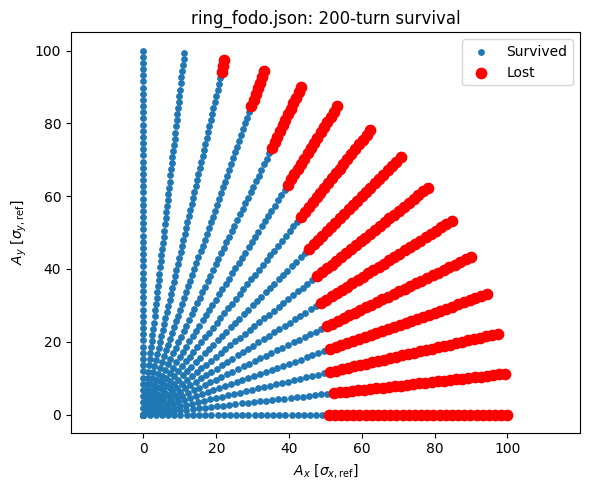

In [19]:
plt.figure(figsize=(6, 5))
plt.scatter(x_normalized[survived], y_normalized[survived],
            color='C0', s=15, label='Survived')
plt.scatter(x_normalized[~survived], y_normalized[~survived],
            color='red', s=55, label='Lost')
plt.xlabel(r'$A_x$ [$\sigma_{x,\mathrm{ref}}$]')
plt.ylabel(r'$A_y$ [$\sigma_{y,\mathrm{ref}}$]')
plt.legend()
plt.title(f'{lattice_file}: {num_turns}-turn survival')
plt.axis('equal')
plt.tight_layout()